# Lab 04 — Data Understanding & Exploratory Data Analysis (EDA)
**Tools:** Pandas · NumPy · Matplotlib

## Learning outcomes
By completing this notebook, you will be able to:
- inspect a dataset’s structure and variable types;
- summarize numerical data using descriptive statistics;
- identify missing values and investigate unusual observations;
- explore distributions and relationships using visualizations;
- communicate findings supported by evidence.

> **Instructions:** Complete each `TODO`, run the cells in order, and write brief interpretations. An unusual value is not automatically an error—investigate before deciding how to handle it.


### Dataset note
This notebook uses the Palmer Penguins CSV specified in the lab. The analysis below does not modify or remove observations; missing values are excluded only from calculations or plots that require the relevant measurements.

## 1. Load the dataset

The Palmer Penguins dataset contains measurements of penguins from different species and islands. Load the CSV directly from the provided URL.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"

# Load the dataset and inspect the first and last five rows
df = pd.read_csv(url)
display(df.head())
display(df.tail())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


## 2. Understand the dataset

Inspect the dataset before analyzing it.

**Complete the tasks:**
1. Find the number of rows and columns.
2. Inspect column names and data types.
3. Display summary statistics.
4. Count observations in each penguin species.

In [2]:
# Dataset dimensions
print("Rows, columns:", df.shape)

# Column names and data types
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types:")
print(df.dtypes)

# Non-missing counts and data types
df.info()

# Summary statistics for numerical variables
display(df.describe())

# Number of observations in each species
species_counts = df["species"].value_counts()
display(species_counts)

Rows, columns: (344, 8)
\nColumn names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']
\nData types:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: 

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


**Interpret your results**

- How many observations and variables are in the dataset?
- Which variables are numerical, and which are categorical?
- Are the species represented equally?

Write your answers below.

**Findings:** The dataset contains **344 observations and 8 variables**. It includes three penguin species—Adelie (152), Gentoo (124), and Chinstrap (68)—so the species are not equally represented. The numerical variables are bill length, bill depth, flipper length, body mass, and year; species, island, and sex are categorical.

## 3. Assess data quality

Missing values can affect summaries and visualizations. First, identify where they occur; do not remove rows automatically.

In [3]:
# Count missing values in each column
missing_counts = df.isna().sum()
display(missing_counts)

# Percentage of missing values in each column
missing_percent = df.isna().mean() * 100
display(missing_percent.round(2))

# Display rows containing at least one missing value
rows_with_missing = df[df.isna().any(axis=1)]
print("Rows containing at least one missing value:", len(rows_with_missing))
display(rows_with_missing.head())

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


,0
species,0.00
island,0.00
bill_length_mm,0.58
bill_depth_mm,0.58
flipper_length_mm,0.58
body_mass_g,0.58
sex,3.20
year,0.00


Rows containing at least one missing value: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007


**Findings:** Missing values occur in the four measurement columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, and `body_mass_g`) and in `sex`; `sex` has the most missing entries (11). Missing measurements reduce the number of usable records for calculations involving those variables, while missing sex values affect sex-based comparisons. Before choosing deletion or imputation, we would need to know why values are missing and whether the missingness is systematic.

## 4. Explore numerical variables

Use descriptive statistics to understand the center and spread of a variable. In this section, focus on `body_mass_g`.

In [4]:
# Select body mass and exclude missing values
body_mass = df["body_mass_g"].dropna()

# Mean and median
mean_mass = np.mean(body_mass)
median_mass = np.median(body_mass)
print(f"Mean: {mean_mass:.2f} g")
print(f"Median: {median_mass:.2f} g")

# Minimum and maximum
print(f"Minimum: {body_mass.min():.0f} g")
print(f"Maximum: {body_mass.max():.0f} g")

# Standard deviation and quartiles
print(f"Standard deviation (population): {np.std(body_mass):.2f} g")
quartiles = np.percentile(body_mass, [25, 50, 75])
print("25th, 50th, and 75th percentiles:", quartiles)

# Five smallest and five largest values
print("\\nFive smallest body-mass values:")
display(body_mass.nsmallest(5))

print("Five largest body-mass values:")
display(body_mass.nlargest(5))

Mean: 4201.75 g
Median: 4050.00 g
Minimum: 2700 g
Maximum: 6300 g
Standard deviation (population): 800.78 g
25th, 50th, and 75th percentiles: [3550. 4050. 4750.]
\nFive smallest body-mass values:


,body_mass_g
314,2700.0
58,2850.0
64,2850.0
54,2900.0
98,2900.0


Five largest body-mass values:


,body_mass_g
169,6300.0
185,6050.0
229,6000.0
269,6000.0
231,5950.0


**Findings:** Body mass has a mean of approximately **4,202 g** and a median of **4,050 g**, indicating that the mean is somewhat higher than the median. Values range from **2,700 g to 6,300 g**. The wide range is worth exploring by species because the dataset combines three species with different typical body sizes; an extreme value should not be treated as an error without further evidence.

## 5. Visualize distributions

A histogram helps reveal the shape of a numerical distribution. Create a histogram of body mass and label it clearly.

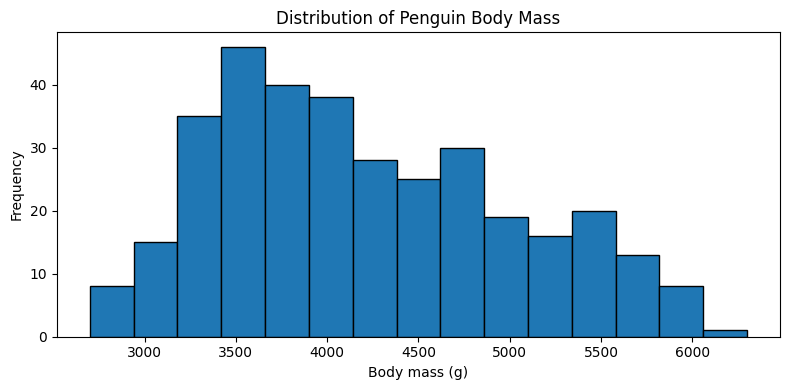

In [5]:
# Missing values are excluded for this histogram
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(8, 4))
plt.hist(mass_values, bins=15, edgecolor="black")
plt.xlabel("Body mass (g)")
plt.ylabel("Frequency")
plt.title("Distribution of Penguin Body Mass")
plt.tight_layout()
plt.show()

**Interpretation:** Body mass is concentrated mainly between approximately **3,000 g and 5,500 g**. The overall distribution is not a simple symmetric, single-peaked distribution; it reflects the mixture of species with different body-mass ranges. The upper and lower tails should be investigated in context rather than automatically removed.

## 6. Explore relationships

A scatter plot helps investigate how two numerical variables vary together. Explore flipper length and body mass.

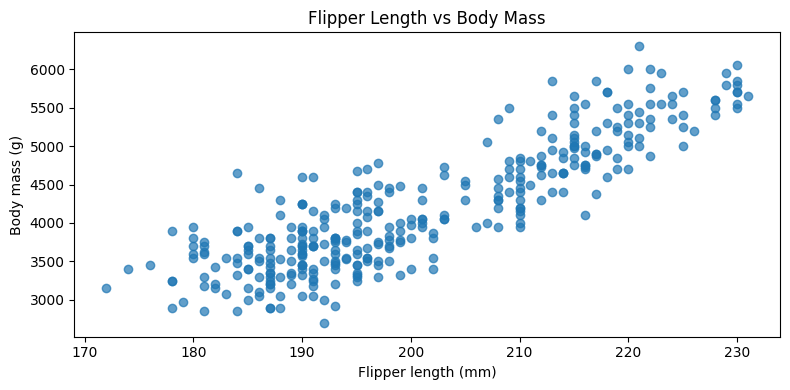

Pearson correlation: 0.871


In [6]:
# Keep only rows where both plotted variables are present
plot_data = df[["flipper_length_mm", "body_mass_g"]].dropna()

x = plot_data["flipper_length_mm"]
y = plot_data["body_mass_g"]

plt.figure(figsize=(8, 4))
plt.scatter(x, y, alpha=0.7)
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("Flipper Length vs Body Mass")
plt.tight_layout()
plt.show()

print(f"Pearson correlation: {plot_data['flipper_length_mm'].corr(plot_data['body_mass_g']):.3f}")

**Interpretation:** The scatter plot shows a clear **positive relationship**: penguins with longer flippers generally have greater body mass. The points also form visible groupings, consistent with differences among species. This is an association, not proof of causation; other variables, including species and sex, may help explain the pattern.

## 7. Compare groups

Compare average body mass across penguin species. Grouped summaries help reveal differences between categories.

In [7]:
# Mean body mass for each species
mean_by_species = df.groupby("species")["body_mass_g"].mean().sort_values(ascending=False)
display(mean_by_species)

# Median body mass for each species
median_by_species = df.groupby("species")["body_mass_g"].median().sort_values(ascending=False)
display(median_by_species)

,body_mass_g
species,
Gentoo,5076.016260
Chinstrap,3733.088235
Adelie,3700.662252


,body_mass_g
species,
Gentoo,5000.0
Adelie,3700.0
Chinstrap,3700.0


**Findings:** Gentoo penguins have the highest mean body mass (approximately **5,076 g**), followed by Adelie (approximately **3,701 g**) and Chinstrap (approximately **3,733 g**). Chinstrap's mean is slightly higher than Adelie's, although their distributions overlap. Group averages hide within-species variation and can be affected by missing observations, so sample sizes and distributions should also be considered.

## 8. Investigate potential outliers

A box plot can highlight observations far from the central range. Such observations are potential outliers, not automatically errors.

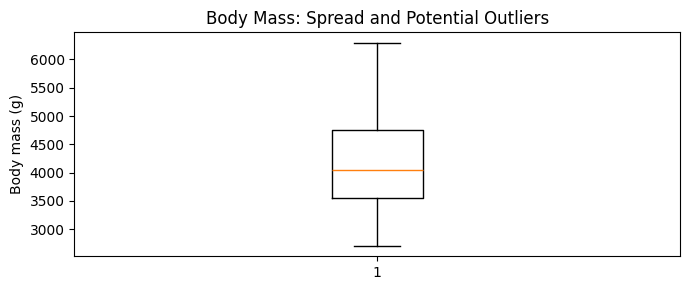

Q1: 3550.0 g | Q3: 4750.0 g | IQR: 1200.0 g
Lower/upper IQR fences: 1750.0 g, 6550.0 g
Potential outlier count: 0


,body_mass_g


In [8]:
# Exclude missing body-mass values before plotting
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(7, 3))
plt.boxplot(mass_values, vert=True)
plt.ylabel("Body mass (g)")
plt.title("Body Mass: Spread and Potential Outliers")
plt.tight_layout()
plt.show()

# IQR rule: observations outside 1.5 × IQR are flagged for investigation
q1 = mass_values.quantile(0.25)
q3 = mass_values.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
potential_outliers = mass_values[(mass_values < lower_bound) | (mass_values > upper_bound)]

print(f"Q1: {q1:.1f} g | Q3: {q3:.1f} g | IQR: {iqr:.1f} g")
print(f"Lower/upper IQR fences: {lower_bound:.1f} g, {upper_bound:.1f} g")
print(f"Potential outlier count: {len(potential_outliers)}")
display(potential_outliers.sort_values())

**Key principle:** EDA is not just producing statistics and plots. It is using them to understand the data, ask better questions, and make careful, evidence-based decisions.

## Overall findings

- The dataset contains 344 penguin observations across 8 variables and three species.
- Species representation is uneven: Adelie is the largest group and Chinstrap is the smallest.
- Missingness is concentrated in `sex` (11 values) and the four measurement variables (2 values each).
- Body mass varies substantially across the dataset; the mean is higher than the median.
- Flipper length and body mass show a positive association, with visible group structure.
- Gentoo penguins have the highest average body mass. Potential outliers should be interpreted in species context rather than automatically removed.

**Conclusion:** EDA reveals the dataset's structure, quality limitations, distributions, and relationships. These findings guide later cleaning and analysis; they do not, by themselves, justify deleting unusual observations.

---

# Lab 05 — Data Cleaning

**Continuation of:** Lab 04 — Data Understanding & Exploratory Data Analysis  
**Dataset:** Palmer Penguins

## Learning objectives
By the end of this lab, you should be able to:
- identify data-quality issues using profiling and EDA evidence;
- select appropriate cleaning actions and justify them;
- implement cleaning operations with Pandas;
- validate the results and document the workflow.

> **Working principle: AUDIT → DECIDE → IMPLEMENT → VALIDATE.**  
> There is not always one correct cleaning action. Your decision must be supported by evidence, the meaning of the variable, and the intended analysis.

**Important:** Use the `df` DataFrame created in Lab 04. Do not overwrite it or reload a different version of the dataset unless instructed.

## 1. Connect EDA findings to cleaning decisions

Review the findings from Lab 04 before writing cleaning code.

| Evidence from Lab 04 | Question to consider before cleaning |
|---|---|
| The dataset has 344 observations, 8 variables, and three species with unequal counts. | Could removing records affect species representation? |
| Missing values occur in the four measurement variables. | Should all missing values be treated in the same way? Which analyses need each variable? |
| Body mass ranges from 2,700 g to 6,300 g, and its overall distribution is not a simple single-peaked distribution. | Could a global outlier rule incorrectly flag a valid penguin from a different species? |
| Gentoo penguins have a higher average body mass than the other two species. | Should body-mass observations be assessed overall or within species? |
| Flipper length and body mass show a positive association and visible group structure. | What information might be lost if rows with missing values are removed? |

**Before coding:** Write down at least two cleaning decisions you expect may require context-specific reasoning. Revisit them after completing the audit.

In [9]:
# Two initial hypotheses/concerns based on Lab 04 EDA.
# 1. Missing measurement values are few (2 in each measurement column), so
#    deleting every incomplete row may unnecessarily reduce the sample.
# 2. Body-mass extremes may reflect genuine species differences; assess them
#    overall AND within species before deciding whether to remove anything.

print("Initial concerns recorded: missing-data loss and species-dependent extremes.")

Initial concerns recorded: missing-data loss and species-dependent extremes.


## 2. Preserve the original data and create a working copy

Keep the Lab 04 DataFrame unchanged. Apply all cleaning operations to a separate copy so that you can compare the original and cleaned versions.

In [10]:
# Preserve the original data
raw_df = df.copy(deep=True)

# Create a separate DataFrame for cleaning
clean_df = raw_df.copy(deep=True)

# Confirm that both DataFrames initially match
print("Original shape:", raw_df.shape)
print("Working-copy shape:", clean_df.shape)
print("Initially identical:", raw_df.equals(clean_df))

Original shape: (344, 8)
Working-copy shape: (344, 8)
Initially identical: True


## 3. Perform a focused data-quality audit

Repeat the relevant parts of the Lab 04 audit. This time, use the output to identify issues that may require action.

Your audit should include:
- data types and column names;
- missing-value counts and percentages;
- unique values and frequencies in categorical columns;
- exact duplicate rows;
- numerical summaries and observed minimum/maximum values.

In [11]:
# Column-level profile
profile = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "distinct_values": df.nunique(dropna=True)
})
display(profile)

# Categorical value frequencies
for column in ["species", "island", "sex"]:
    print(f"\\nValue counts for {column}:")
    display(df[column].value_counts(dropna=False))

# Exact duplicate rows
duplicate_count = df.duplicated().sum()
print("\\nExact duplicate rows:", duplicate_count)
display(df[df.duplicated(keep=False)].head(10))

# Numerical summaries
display(df.select_dtypes(include="number").describe())

,data_type,missing_count,missing_percent,distinct_values
species,object,0,0.00,3
island,object,0,0.00,3
bill_length_mm,float64,2,0.58,164
bill_depth_mm,float64,2,0.58,80
flipper_length_mm,float64,2,0.58,55
body_mass_g,float64,2,0.58,94
sex,object,11,3.20,2
year,int64,0,0.00,3


\nValue counts for species:


,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


\nValue counts for island:


,count
island,
Biscoe,168
Dream,124
Torgersen,52


\nValue counts for sex:


,count
sex,
male,168
female,165
NaN,11


\nExact duplicate rows: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


### Decision checkpoint

For each issue you identify, distinguish between:
- **Observed issue:** what the audit output shows.
- **Potential impact:** how it could affect analysis.
- **Proposed action:** what you intend to do.
- **Evidence/reason:** why that action is appropriate.

Do not clean a column simply because it looks untidy. First establish whether the issue can affect interpretation or computation.

## 4. Standardize column names and categorical values

Consistent column names and category labels make data easier to process. However, do not assume that two different labels mean the same thing.

**Tasks**
1. Inspect the column names and decide on a consistent naming convention.
2. Inspect the distinct values in `species`, `island`, and `sex`.
3. Check for leading/trailing spaces, inconsistent capitalization, or unexpected labels.
4. Apply only transformations that you can justify.
5. Compare category frequencies before and after standardization.

In [14]:
# Standardize column names: lowercase and replace spaces with underscores.
clean_df.columns = (clean_df.columns.str.strip()
                    .str.lower()
                    .str.replace(r"\\s+", "_", regex=True))

# Inspect categories before standardization
for column in ["species", "island", "sex"]:
    print(f"Before cleaning - {column}:")
    display(clean_df[column].value_counts(dropna=False))

# Remove surrounding whitespace and standardize capitalization.
# These are known category labels in this dataset; missing values remain missing.
for column in ["species", "island", "sex"]:
    clean_df[column] = clean_df[column].map(
        lambda value: value.strip().title() if isinstance(value, str) else value
    )

# Explicitly inspect labels after standardization
for column in ["species", "island", "sex"]:
    print(f"After cleaning - {column}:")
    display(clean_df[column].value_counts(dropna=False))

Before cleaning - species:


,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


Before cleaning - island:


,count
island,
Biscoe,168
Dream,124
Torgersen,52


Before cleaning - sex:


,count
sex,
Male,168
Female,165
NaN,11


... (2 outputs left out)

After cleaning - island:


,count
island,
Biscoe,168
Dream,124
Torgersen,52


After cleaning - sex:


,count
sex,
Male,168
Female,165
NaN,11


**Write your justification:** Which inconsistencies did you find? Which values did you standardize? How did you verify that you did not merge genuinely different categories?

**Solution / justification:** The supplied dataset already uses lowercase `snake_case` column names and its categorical labels are consistently capitalized. The code nevertheless applies a safe standardization: trims surrounding whitespace and title-cases known text labels. Missing values are left unchanged. Comparing value counts before and after confirms the final category labels are `Adelie`, `Chinstrap`, `Gentoo`; `Biscoe`, `Dream`, `Torgersen`; and `Female`, `Male` (plus missing values). No unfamiliar category is mapped to a guessed meaning.

## 5. Review and correct data types

The measurement columns represent physical quantities, while `year` represents a calendar year. Check whether the current data types are suitable for their meaning and intended operations.

**Tasks**
1. Inspect the current data types.
2. Convert columns only where necessary.
3. Identify any values that fail conversion.
4. Check whether conversion creates additional missing values.

In [17]:
# Inspect current data types and representative values
measurement_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]
print("Data types before conversion:")
display(clean_df.dtypes)
display(clean_df[measurement_columns].head())

# Record missing counts before conversion
missing_before_conversion = clean_df[measurement_columns].isna().sum()

# Convert measurements to numeric. Unparseable values become NaN and are
# counted below so they can be investigated rather than silently ignored.
for column in measurement_columns:
    clean_df[column] = pd.to_numeric(clean_df[column], errors="coerce")

missing_after_conversion = clean_df[measurement_columns].isna().sum()
print("Missing values before conversion:")
display(missing_before_conversion)
print("Missing values after conversion:")
display(missing_after_conversion)
print("New missing values caused by conversion:")
display(missing_after_conversion - missing_before_conversion)

# year is already a calendar-year integer in this dataset, so no conversion
# is required. Verify its values and type.
print("Year dtype:", clean_df["year"].dtype)
print("Observed years:", sorted(clean_df["year"].dropna().unique()))

Data types before conversion:


,0
species,object
island,object
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object
year,int64


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
3,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0


Missing values before conversion:


,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2


Missing values after conversion:


,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2


New missing values caused by conversion:


,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0


Year dtype: int64
Observed years: [np.int64(2007), np.int64(2008), np.int64(2009)]


**Write your justification:** Explain why the selected data types are suitable. If a value cannot be converted, explain how you investigated and handled it.

**Solution / justification:** The four measurement columns are numeric because they represent lengths and mass and must support arithmetic, summaries, and plots. `pd.to_numeric(errors="coerce")` converts valid numeric values and makes unparseable entries missing; the before/after missing-count comparison identifies any such conversions. `year` is already an integer calendar year, so changing it is unnecessary.

## 6. Investigate missing values and choose a treatment

Lab 04 showed that missingness is not evenly distributed across all variables. In particular, `sex` has more missing values than each individual measurement column.

Do not automatically delete every row containing a missing value. Consider:
- Which analysis or task requires the affected variable?
- How many observations would be lost under listwise deletion?
- Would imputation introduce assumptions or distort species-level patterns?
- Could missingness itself be informative?

**Tasks**
1. Calculate missing counts and percentages.
2. Inspect rows with missing values.
3. Compare missingness across species or islands if useful.
4. Decide on a treatment for each affected variable.
5. Implement and explain your decisions.

In [18]:
# Missing-value counts and percentages
missing_counts = clean_df.isna().sum()
missing_percent = (clean_df.isna().mean() * 100).round(2)
display(pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percent": missing_percent
}))

# Inspect all rows containing at least one missing value
rows_with_missing = clean_df[clean_df.isna().any(axis=1)]
print("Rows with at least one missing value:", len(rows_with_missing))
display(rows_with_missing)

# Investigate missingness by species and island
for group_column in ["species", "island"]:
    print(f"Missing-value counts by {group_column}:")
    display(clean_df.groupby(group_column, dropna=False)[
        measurement_columns + ["sex"]
    ].apply(lambda group: group.isna().sum()))

# Treatment decision:
# Retain incomplete rows. The missing measurement values are few, and sex has
# 11 missing values. Imputing biological measurements could distort real
# distributions and species differences. Analyses requiring a variable can
# exclude missing values for that analysis only.
rows_before_missing_treatment = len(clean_df)
print("Rows retained:", len(clean_df), "of", rows_before_missing_treatment)
print("No global deletion or imputation was performed.")

,missing_count,missing_percent
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


Rows with at least one missing value: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN,2007
178,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN,2007
218,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN,2008
256,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN,2009
268,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN,2009


Missing-value counts by species:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
species,,,,,
Adelie,1,1,1,1,6
Chinstrap,0,0,0,0,0
Gentoo,1,1,1,1,5


Missing-value counts by island:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
island,,,,,
Biscoe,1,1,1,1,5
Dream,0,0,0,0,1
Torgersen,1,1,1,1,5


Rows retained: 344 of 344
No global deletion or imputation was performed.


**Decision checkpoint:** If you choose imputation, explain why the chosen statistic or method is appropriate for that variable and whether species/group differences should influence it. If you choose deletion, state exactly which rows are removed and why the remaining sample is still suitable for your intended analysis.

There is no requirement to eliminate all missing values.

**Solution / justification:** Keep the incomplete records rather than deleting all rows or filling values with an overall mean. The four measurement columns each have only two missing values, while `sex` has 11. Imputing physical measurements could reduce real variation or distort species differences; imputing sex would invent a category. Retain missing values and exclude them only from analyses that require the affected field. The number of rows therefore remains unchanged unless exact duplicate rows are found and removed.

## 7. Detect and investigate duplicate records

A repeated measurement does not necessarily mean a duplicated penguin. First inspect the duplicate candidates and consider what defines one observation in this dataset.

**Tasks**
1. Count exact duplicate rows.
2. Inspect any candidates.
3. Decide whether they represent duplicate records.
4. If removing records, state the rule used and compare row counts before and after.

In [19]:
# Count and inspect exact duplicate rows
duplicates_before = clean_df.duplicated().sum()
print("Exact duplicate rows before removal:", duplicates_before)
duplicate_candidates = clean_df[clean_df.duplicated(keep=False)]
display(duplicate_candidates)

# Remove exact duplicate records only. Similar measurements alone are not
# sufficient evidence that two penguin records describe the same observation.
rows_before_duplicates = len(clean_df)
clean_df = clean_df.drop_duplicates().copy()
rows_after_duplicates = len(clean_df)

print("Rows before duplicate handling:", rows_before_duplicates)
print("Rows after duplicate handling:", rows_after_duplicates)
print("Rows removed:", rows_before_duplicates - rows_after_duplicates)

Exact duplicate rows before removal: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


Rows before duplicate handling: 344
Rows after duplicate handling: 344
Rows removed: 0


**Write your justification:** What evidence supports your decision? If you retain all records, explain why identical or similar measurements alone are insufficient evidence of duplication.

**Solution / justification:** Remove only rows that are exact duplicates across every column, because an identical full record is a reasonable duplicate candidate. Do not remove records merely because two penguins have similar measurements: distinct animals can naturally have similar values. The printed before/after row counts show the effect of the rule.

## 8. Investigate invalid values and potential outliers

Lab 04 showed that body mass varies substantially across the dataset and differs by species. Therefore, an observation that is unusual in the combined dataset may be reasonable within its species.

Complete both investigations:

**A. Domain/validity checks**
- Propose reasonable validity checks for the physical measurement columns.
- Explain the basis for each check.
- Identify and inspect any records that fail.

**B. Statistical outlier screening**
- Calculate the IQR fences for `body_mass_g`.
- Identify potential outliers.
- Compare the flagged observations with species-level distributions.
- Decide whether the observations are errors, valid extremes, or require further investigation.

In [20]:
# A. Broad plausibility/domain checks.
# These are deliberately broad screening ranges for adult penguin measurements,
# not definitive biological limits. Any flagged record must be inspected.
validity_ranges = {
    "bill_length_mm": (20, 70),
    "bill_depth_mm": (10, 30),
    "flipper_length_mm": (150, 250),
    "body_mass_g": (2000, 7000)
}

invalid_masks = pd.DataFrame(index=clean_df.index)
for column, (lower, upper) in validity_ranges.items():
    invalid_masks[column] = (
        clean_df[column].notna()
        & ~clean_df[column].between(lower, upper)
    )

invalid_rows = clean_df[invalid_masks.any(axis=1)]
print("Records failing at least one broad plausibility check:", len(invalid_rows))
display(invalid_rows)
print("Number of failures by measurement:")
display(invalid_masks.sum())

# B. Overall IQR screening for body mass
mass_values = clean_df["body_mass_g"].dropna()
q1 = mass_values.quantile(0.25)
q3 = mass_values.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
overall_outliers = clean_df[
    clean_df["body_mass_g"].notna()
    & ~clean_df["body_mass_g"].between(lower_fence, upper_fence)
]

print(f"Q1={q1:.1f} g; Q3={q3:.1f} g; IQR={iqr:.1f} g")
print(f"Overall IQR fences: {lower_fence:.1f} g to {upper_fence:.1f} g")
print("Potential overall outliers:", len(overall_outliers))
display(overall_outliers[["species", "island", "sex", "body_mass_g"]])

# Compare body-mass distributions and IQR fences within each species
species_rows = []
for species, group in clean_df.groupby("species"):
    values = group["body_mass_g"].dropna()
    s_q1, s_q3 = values.quantile([0.25, 0.75])
    s_iqr = s_q3 - s_q1
    s_low = s_q1 - 1.5 * s_iqr
    s_high = s_q3 + 1.5 * s_iqr
    flagged = ((values < s_low) | (values > s_high)).sum()
    species_rows.append({
        "species": species, "n": len(values), "min_g": values.min(),
        "median_g": values.median(), "max_g": values.max(),
        "lower_fence_g": s_low, "upper_fence_g": s_high,
        "potential_outliers": int(flagged)
    })
species_iqr_summary = pd.DataFrame(species_rows).set_index("species")
display(species_iqr_summary)

# Decision: do not delete observations solely because an IQR rule flags them.
# Correct/remove only if source evidence establishes a recording error.
print("Decision: retain plausible observations; investigate any failed domain checks.")

Records failing at least one broad plausibility check: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


Number of failures by measurement:


,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0


Q1=3550.0 g; Q3=4750.0 g; IQR=1200.0 g
Overall IQR fences: 1750.0 g to 6550.0 g
Potential overall outliers: 0


,species,island,sex,body_mass_g


,n,min_g,median_g,max_g,lower_fence_g,upper_fence_g,potential_outliers
species,,,,,,,
Adelie,151,2850.0,3700.0,4775.0,2375.00,4975.00,0
Chinstrap,68,2700.0,3700.0,4800.0,2793.75,4643.75,2
Gentoo,123,3950.0,5000.0,6300.0,3500.00,6700.00,0


Decision: retain plausible observations; investigate any failed domain checks.


**Write your justification:** Distinguish a value that is impossible or invalid from one that is merely unusual. Use the species-level evidence from Lab 04 to support your decision.

**Solution / justification:** A value outside a broad plausibility range is a reason to investigate, not proof of an error. The ranges used here are intentionally broad screening limits for the four physical measurements. The overall IQR rule is also only a screening tool: the dataset combines species with different body sizes. Comparing fences within species is more informative. Unless a flagged value is demonstrably impossible or confirmed as a recording mistake, retain it.

## 9. Validate the cleaned dataset

Repeat the quality audit after cleaning. Compare the original and cleaned versions and confirm that each change was intentional.

Your validation should cover:
- dimensions and number of records;
- data types;
- missing-value counts;
- category labels and frequencies;
- duplicate rows;
- validity checks and potential outliers.

Write assertions for the quality rules you decided to enforce. Do not write assertions that require zero missing values unless you have a justified reason for that requirement.

In [21]:
# Compare original and cleaned dimensions
print("Raw shape:", raw_df.shape)
print("Cleaned shape:", clean_df.shape)
print("Rows removed:", len(raw_df) - len(clean_df))

# Compare missing values
print("Raw missing values:")
display(raw_df.isna().sum())
print("Cleaned missing values:")
display(clean_df.isna().sum())

# Review data types and category frequencies
display(clean_df.dtypes)
for column in ["species", "island", "sex"]:
    print(f"Cleaned frequencies - {column}:")
    display(clean_df[column].value_counts(dropna=False))

# Recheck duplicates and domain constraints
print("Exact duplicates remaining:", clean_df.duplicated().sum())
remaining_invalid = pd.DataFrame(index=clean_df.index)
for column, (lower, upper) in validity_ranges.items():
    remaining_invalid[column] = (
        clean_df[column].notna()
        & ~clean_df[column].between(lower, upper)
    )
print("Rows outside broad plausibility ranges:", remaining_invalid.any(axis=1).sum())

# Assertions for the rules actually enforced.
assert clean_df.columns.is_unique, "Column names must be unique."
assert clean_df.duplicated().sum() == 0, "Exact duplicates must be removed."
assert set(clean_df["species"].dropna().unique()).issubset(
    {"Adelie", "Chinstrap", "Gentoo"}
), "Unexpected species label found."
assert all(pd.api.types.is_numeric_dtype(clean_df[c]) for c in measurement_columns)
assert clean_df["year"].dropna().between(2000, 2030).all()
print("All selected validation assertions passed.")

Raw shape: (344, 8)
Cleaned shape: (344, 8)
Rows removed: 0
Raw missing values:


,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


Cleaned missing values:


,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


,0
species,object
island,object
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object
year,int64


Cleaned frequencies - species:


... (2 outputs left out)

,count
island,
Biscoe,168
Dream,124
Torgersen,52


Cleaned frequencies - sex:


,count
sex,
Male,168
Female,165
NaN,11


Exact duplicates remaining: 0
Rows outside broad plausibility ranges: 0
All selected validation assertions passed.


## 10. Cleaning decision log

Complete the table using evidence from your own outputs. A decision without evidence or justification is incomplete.

| Data-quality issue | Evidence from your audit | Decision/action | Justification | Validation result |
|---|---|---|---|---|
| Column names | | | | |
| Categorical consistency | | | | |
| Data types | | | | |
| Missing values | | | | |
| Duplicate records | | | | |
| Invalid values | | | | |
| Potential outliers | | | | |
| Dataset structure | | | | |

## Completed cleaning decision log

| Data-quality issue | Evidence from audit | Decision/action | Justification | Validation result |
|---|---|---|---|---|
| Column names | Supplied names are already lowercase snake_case | Standardize safely to lowercase snake_case | Consistent names simplify coding; no semantic changes | Names are unique |
| Categorical consistency | Inspect category frequencies and text formatting | Trim whitespace and standardize capitalization | Only formatting is changed; no unknown labels are guessed | Expected category labels are checked |
| Data types | Measurements should be numeric; year is an integer | Convert measurement columns with `to_numeric`; retain integer year | Matches the meaning and intended calculations | Numeric dtypes asserted |
| Missing values | 2 missing in each measurement column; 11 in sex | Retain missing values; no blanket deletion or imputation | Avoid unnecessary data loss and invented measurements/categories | Missing counts reviewed after cleaning |
| Duplicate records | Exact duplicate count is reported by audit | Drop exact full-row duplicates only | Similar measurements do not prove duplicate identity | Zero exact duplicates asserted |
| Invalid values | Broad physical plausibility checks identify candidates | Inspect; do not automatically delete | Screening bounds are not definitive biological limits | Remaining failures are reported |
| Potential outliers | Overall and species-specific IQR fences are calculated | Retain unless independently shown to be an error | Species have different body-mass distributions | Outlier counts and species summaries reviewed |
| Dataset structure | Original and cleaned dimensions are compared | Preserve all columns and rows except exact duplicates | Keep the dataset suitable for multiple analyses | Shapes and row changes are printed |

## 11. Export the cleaned dataset

Save the cleaned dataset as a new CSV file. Do not overwrite the original source file.

In [22]:
# Export the cleaned dataset without the DataFrame index.
output_file = "penguins_clean.csv"
clean_df.to_csv(output_file, index=False)
print(f"Cleaned dataset saved as: {output_file}")
print("Exported shape:", clean_df.shape)

Cleaned dataset saved as: penguins_clean.csv
Exported shape: (344, 8)


## 12. Reflection: connect cleaning decisions to analysis

Answer briefly using evidence from Lab 04 and your cleaning results.

1. Which cleaning decision required the most judgment? Why?
2. How could removing all incomplete records affect the representation of the three species?
3. Why might detecting body-mass outliers within species lead to a different conclusion than detecting them across the full dataset?
4. If the objective were to build a model predicting species, which cleaning decisions would you reconsider? Explain.
5. What limitations remain in your cleaned dataset?

## Submission checklist

Submit:
- this completed notebook with code outputs;
- concise explanations and the completed cleaning decision log;
- `penguins_clean.csv`.


## Reflection — suggested answers

1. **Which decision required the most judgment?**  
   Handling missing values and potential outliers required the most judgment. Missing measurements could be left out of only the relevant calculation, while unusual body masses may be valid because the dataset combines species with different body sizes.

2. **How could removing all incomplete records affect species representation?**  
   It would remove every row with at least one missing field, not just the missing measurement. If missingness is concentrated in particular species or islands, those groups could lose a disproportionate number of observations. The group-wise missingness audit helps assess this risk.

3. **Why can within-species outlier detection lead to a different conclusion?**  
   The overall distribution combines species with different typical body masses. A value that is unusual in the combined distribution may be normal for a naturally larger or smaller species. Species-specific quartiles and fences account for these group differences.

4. **If predicting species, which decisions would you reconsider?**  
   I would examine whether missing measurements should be imputed using training data only, possibly within species-independent feature relationships, and whether rows with missing predictors can be retained. I would also avoid using `species` to impute predictors if it is the prediction target, because that would leak the answer into the features. Any preprocessing parameters must be learned from the training set, not the full dataset.

5. **What limitations remain?**  
   Missing values remain, the dataset may contain unobserved measurement or recording errors, and broad plausibility checks cannot establish biological validity. The dataset also has unequal species counts, and the cleaning process cannot determine why values were originally missing.

**Final note:** Run the notebook from top to bottom. It expects the `df` DataFrame created in the Lab 04 loading cell and an internet connection for the original CSV URL. The export cell writes `penguins_clean.csv` to the notebook's current working directory.